In [1]:
import pandas as pd

# 1. Load dataset
df = pd.read_csv("uber (1).csv")

print("Original shape:", df.shape)
print("\nColumn data types:")
print(df.dtypes)

# 2. Missing values and duplicates
print("\nMissing values:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

# 3. Convert pickup datetime
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"],
    errors="coerce",
    utc=True
)

# 4. Define validation rules
coordinates = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude"
]

# This geographic boundary is an assumption
# for this NYC-focused dataset.
nyc_coordinates = (
    df["pickup_longitude"].between(-74.3, -73.5)
    & df["pickup_latitude"].between(40.4, 41.0)
    & df["dropoff_longitude"].between(-74.3, -73.5)
    & df["dropoff_latitude"].between(40.4, 41.0)
)

valid_fare = df["fare_amount"] > 0
valid_passengers = df["passenger_count"].between(1, 6)
valid_coordinates = (
    df[coordinates].notna().all(axis=1)
    & nyc_coordinates
)
valid_datetime = df["pickup_datetime"].notna()

# 5. Create a validation summary
print("\nVALIDATION SUMMARY")
print("Invalid fare:", (~valid_fare).sum())
print("Invalid passenger count:", (~valid_passengers).sum())
print("Invalid coordinates:", (~valid_coordinates).sum())
print("Invalid datetime:", (~valid_datetime).sum())

# 6. Filter records according to the documented rules
valid_rows = (
    valid_fare
    & valid_passengers
    & valid_coordinates
    & valid_datetime
)

cleaned_df = df.loc[valid_rows].copy()

# Remove a likely exported index column
if "Unnamed: 0" in cleaned_df.columns:
    cleaned_df.drop(columns=["Unnamed: 0"], inplace=True)

# 7. Export cleaned data
cleaned_df.to_csv("uber_cleaned.csv", index=False)

print("\nOriginal records:", len(df))
print("Cleaned records:", len(cleaned_df))
print("Removed records:", len(df) - len(cleaned_df))
print("Saved as uber_cleaned.csv")

Original shape: (200000, 9)

Column data types:
Unnamed: 0             int64
key                      str
fare_amount          float64
pickup_datetime          str
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

Missing values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

Exact duplicate rows: 0

VALIDATION SUMMARY
Invalid fare: 22
Invalid passenger count: 710
Invalid coordinates: 4348
Invalid datetime: 0

Original records: 200000
Cleaned records: 194946
Removed records: 5054
Saved as uber_cleaned.csv


In [2]:

pip install pandas numpy matplotlib seaborn scikit-learn joblib


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("uber_cleaned.csv")

# Convert pickup time
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

# Remove rows with missing essential fields
required = [
    "fare_amount", "pickup_datetime", "passenger_count",
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude"
]
df = df.dropna(subset=required).copy()

# Extract time-based features
df["pickup_hour"] = df["pickup_datetime"].dt.hour
df["pickup_day"] = df["pickup_datetime"].dt.dayofweek
df["pickup_month"] = df["pickup_datetime"].dt.month
df["is_weekend"] = (df["pickup_day"] >= 5).astype(int)

# Calculate approximate trip distance using Haversine formula
def haversine_distance(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius_km * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

df["trip_distance_km"] = haversine_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

print("Dataset shape:", df.shape)
print("\nNew features:")
print(df[[
    "pickup_hour", "pickup_day", "pickup_month",
    "is_weekend", "trip_distance_km"
]].head())

print("\nSummary statistics:")
print(df[["fare_amount", "trip_distance_km"]].describe())


Dataset shape: (194946, 13)

New features:
   pickup_hour  pickup_day  pickup_month  is_weekend  trip_distance_km
0           19           3             5           0          1.683323
1           20           4             7           0          2.457590
2           21           0             8           0          5.036377
3            8           4             6           0          1.661683
4           17           3             8           0          4.475450

Summary statistics:
         fare_amount  trip_distance_km
count  194946.000000     194946.000000
mean       11.328245          3.314629
std         9.637821          3.577654
min         0.010000          0.000000
25%         6.000000          1.256547
50%         8.500000          2.157408
75%        12.500000          3.907445
max       499.000000         41.225208


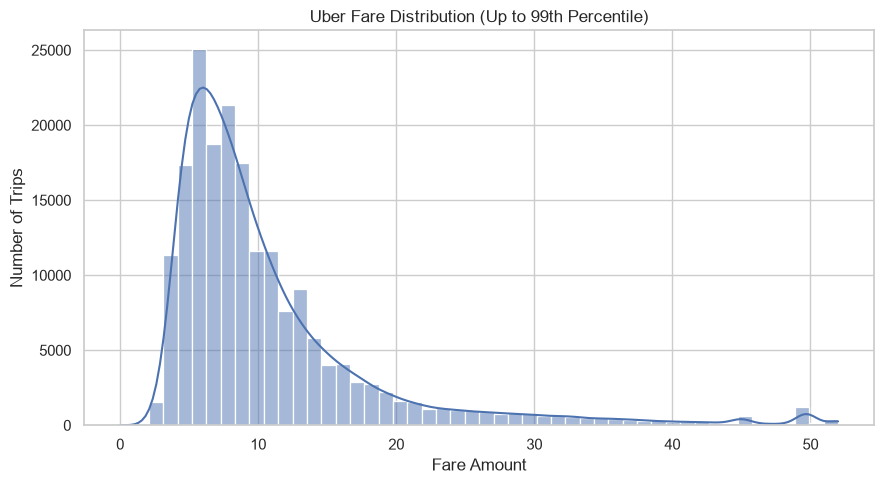

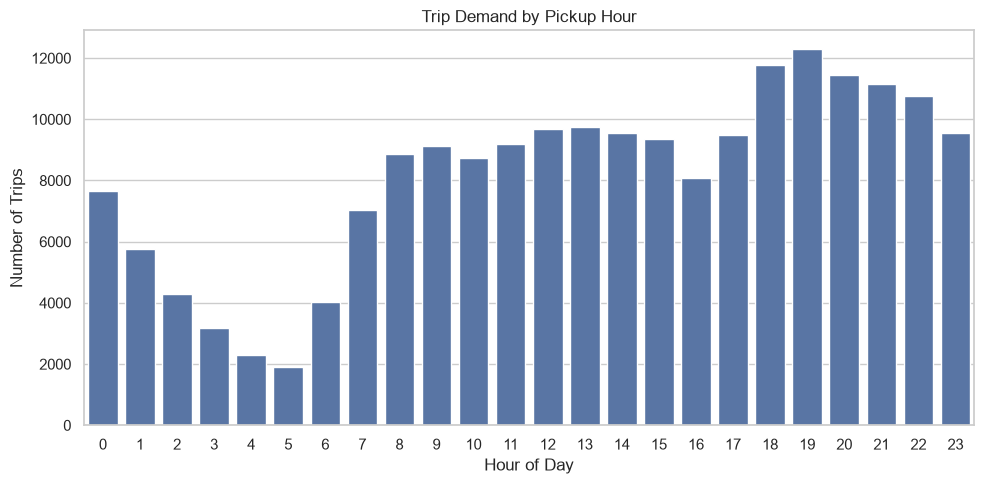

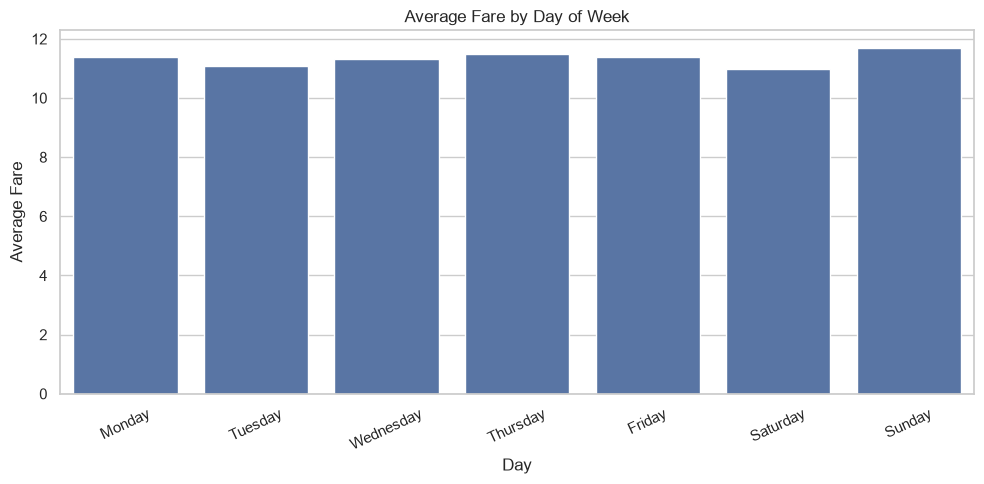

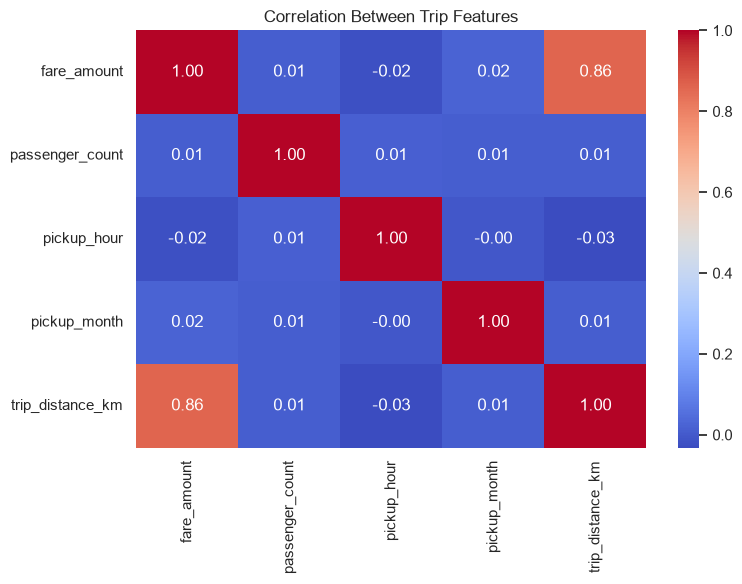

In [4]:

sns.set_theme(style="whitegrid")

# 1. Fare distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df[df["fare_amount"] <= df["fare_amount"].quantile(0.99)],
    x="fare_amount", bins=50, kde=True
)
plt.title("Uber Fare Distribution (Up to 99th Percentile)")
plt.xlabel("Fare Amount")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

# 2. Trips by hour
plt.figure(figsize=(10, 5))
hour_counts = df.groupby("pickup_hour").size()
sns.barplot(x=hour_counts.index, y=hour_counts.values)
plt.title("Trip Demand by Pickup Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

# 3. Average fare by weekday
weekday_names = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_fares = (
    df.groupby("pickup_day")["fare_amount"]
      .mean()
      .reindex(range(7))
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=weekday_names,
    y=weekday_fares.values
)
plt.title("Average Fare by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Fare")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 4. Correlation heatmap
corr_cols = [
    "fare_amount", "passenger_count", "pickup_hour",
    "pickup_month", "trip_distance_km"
]

plt.figure(figsize=(8, 6))
sns.heatmap(
    df[corr_cols].corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Correlation Between Trip Features")
plt.tight_layout()
plt.show()
